In [5]:
import numpy as np
import seaborn as sns
import pandas as pd

In [ ]:
class KNN_cls:
    def __init__(self, k = 3):
        self.k = k

    def fit(self, X_train, y_train):
        self.X_train = X_train
        self.y_train = y_train

    def _distance(self, x1, x2):
        return np.sqrt(np.sum(x1 - x2) ** 2)

    def _predict_one(self, x_test):
        distances = [self._distance(x_test, x_train) for x_train in self.X_train]
        knn_indices = np.argsort(distances)[:self.k]

        knn_classes = [self.y_train[i] for i in knn_indices]
        majority_classes = np.argmax(np.bincount(knn_classes))
        return majority_classes

    def predict(self, X_test):
       return [self._predict_one(x) for x in X_test]
       


<Axes: xlabel='x1', ylabel='x2'>

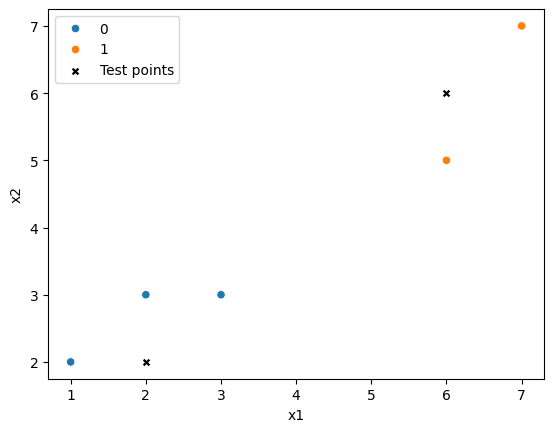

In [13]:
X_train = np.array([
    [1, 2],
    [2, 3],
    [3, 3],
    [6, 5],
    [7, 7]
])

y_train = np.array([0, 0, 0, 1, 1])

X_test = np.array([
    [2, 2],
    [6, 6]
])

df = pd.DataFrame(X_train, columns=["x1", "x2"])
df["labels"] = y_train

sns.scatterplot(
    data = df,
    x="x1",
    y="x2",
    hue="labels",
)

X_test_df = pd.DataFrame(X_test, columns=["x1", "x2"])

sns.scatterplot(
    data=X_test_df,
    x="x1",
    y="x2",
    color="black", 
    marker="X",
    label="Test points"
)

In [16]:
model = KNN()
model.fit(X_train, y_train)
model.predict(X_test)

[np.int64(0), np.int64(1)]